In [1]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

In [2]:
df = pd.read_excel('../data/record.xlsx')
df.shape

(38493, 14)

#### 연도는 출항일시 기준

In [3]:
df['체류시간'] = (df['출항일시'] - df['입항일시']).dt.total_seconds() / 3600
df['연도'] = df['출항일시'].dt.year
df['부두'] = df['계선장소.2'].str.extract(r'(\d+)부두')[0].astype(int)
df[['출항일시', '연도', '계선장소.2', '부두', '체류시간']].head()

,출항일시,연도,계선장소.2,부두,체류시간
0,2020-01-01 10:13:00,2020,신항 5부두 3선석,5,41.216667
1,2020-01-01 03:00:00,2020,신항 1부두 3선석,1,27.000000
2,2020-01-01 01:15:00,2020,신항 1부두 1선석,1,24.333333
3,2020-01-01 13:00:00,2020,신항 2부두 4선석,2,31.000000
4,2020-01-01 10:25:00,2020,신항 2부두 1선석,2,27.416667


In [4]:
table = df.pivot_table(index='연도', columns='부두', values='체류시간', aggfunc='mean').round(2)
table

부두,1,2,3,4,5,6,7
연도,,,,,,,
2020,23.88,22.95,19.35,23.79,26.57,NaN,NaN
2021,29.28,25.18,23.91,29.44,28.07,NaN,NaN
2022,28.97,21.36,22.97,25.87,29.16,28.78,NaN
2023,26.74,23.74,22.09,23.52,24.96,24.64,NaN
2024,29.38,23.68,23.76,23.30,24.39,25.90,27.68
2025,31.41,27.95,22.22,23.25,23.45,31.06,22.84
2026,30.70,28.90,20.30,24.73,23.18,32.06,22.89


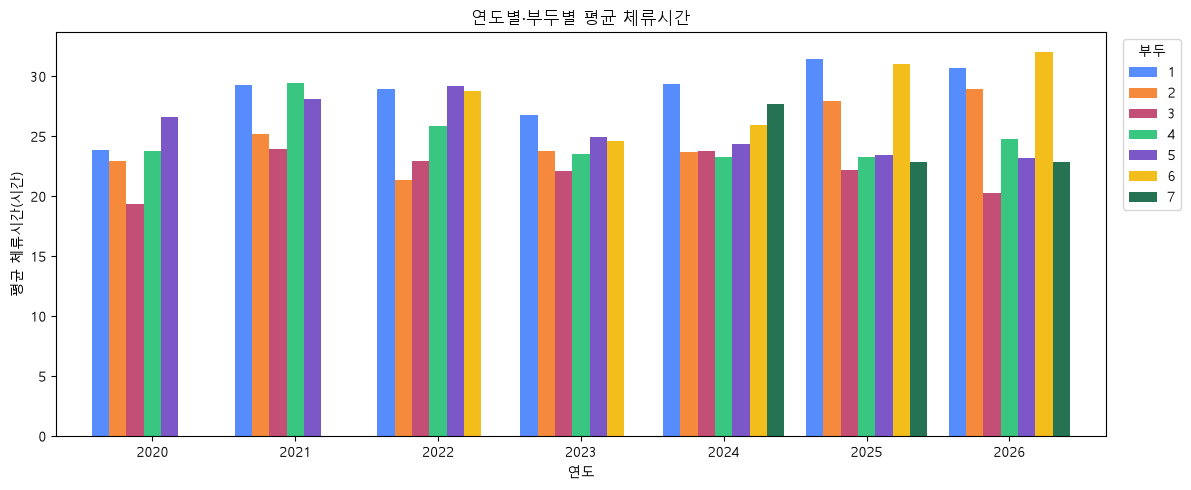

In [5]:
ax = table.plot(kind='bar', figsize=(12, 5), width=0.85)
ax.set_xlabel('연도')
ax.set_ylabel('평균 체류시간(시간)')
ax.set_title('연도별·부두별 평균 체류시간')
ax.legend(title='부두', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

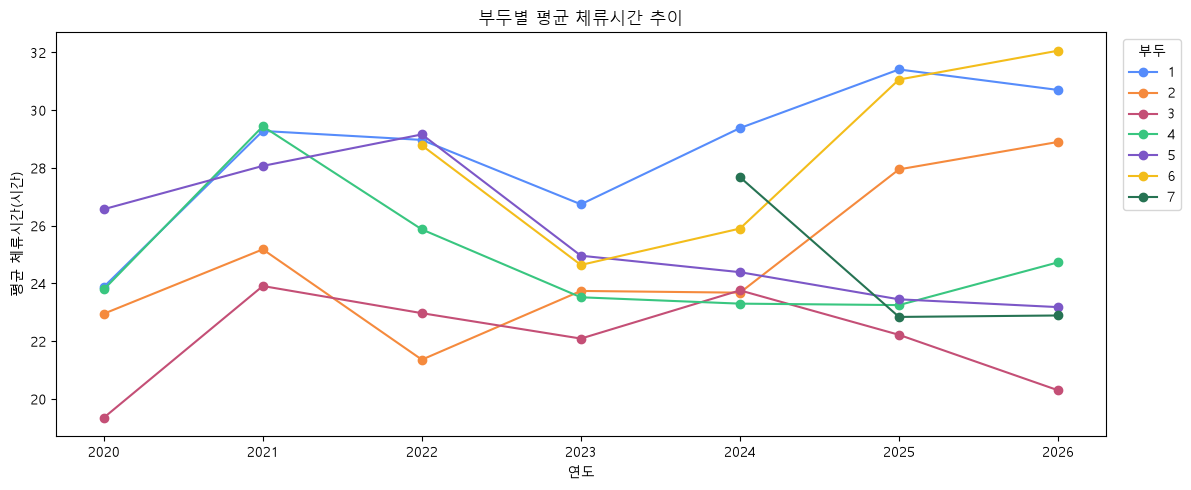

In [6]:
ax = table.plot(kind='line', marker='o', figsize=(12, 5))
ax.set_xlabel('연도')
ax.set_ylabel('평균 체류시간(시간)')
ax.set_title('부두별 평균 체류시간 추이')
ax.legend(title='부두', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.show()

#### 현재상황
자동화가 적용됨에 따라 물동량의 증가와 재항시간의 감소를 기대했으나, 현상은 기대했던 지표와 반대로 나타났다.
신항 1부두 : 2018년 대비 자동화 후 물동량 감소, 재항시간 증가
신항 7부두 : AGV까지 적용된 현재 '완전 자동화'에 가까운 부두. 그러나 6부두에 비해 물동량이 현저히 적고, 아직 누적된 데이터가 부족해서 유의미한 분석이 어렵다.

싱가포르 투아스항은 부산항이 목표로 해야할 대표적인 스마트 항만으로 평가된다.
그 이유와 제약, 한계점은 몇 가지로 나타난다.

심효상 교수님 - 모든 연구와 발표들이 자동화하는 방향으로 나아가야 함을 제시하고 있다. 초기비용과 현재 효율성을 감안하더라도!
우철승 강사님 - 데이터 분석에 더 무게를 두어도 상관없다. 하지만 결론은 있어야 한다. 완전한 문제 해결책을 제시할 필요 없다!